#TakarMobil: Evaluasi & Analisis Komprehensif Model (Phase 5)
**Proyek Akhir Machine Learning - Semester 5 | Kelas B2 - Kelompok 15**  
*TakarMobil: Sistem Estimasi Rentang Harga & Analisis Faktor Penentu Harga Mobil Bekas*

---

### 🎯 Tujuan Tahap Evaluasi & Analisis (Sesuai Ketentuan Dosen Poin 9 & 10):
1. **Perbandingan Metrik Lengkap:** Menghitung MAE, MSE, RMSE, dan $R^2$ untuk seluruh model (Baseline, Ridge, Decision Tree, Random Forest, XGBoost) pada data uji independen.
2. **Visualisasi Metrik:** Menyajikan bar chart perbandingan metrik kinerja antar-model.
3. **Actual vs Predicted Plot:** Mengukur keselarasan nilai prediksi model terbaik terhadap harga pasar riil.
4. **Analisis Pola Residual (Galat):** Memeriksa kurva sebaran error dan homoskedastisitas untuk mendeteksi kecenderungan bias.
5. **Analisis Overfitting vs Underfitting (Learning Curve):** Menguji generalisasi model terhadap penambahan data latih.
6. **Analisis Faktor Penentu (*Feature Importance*):** Mengidentifikasi variabel paling berpengaruh terhadap harga mobil bekas.
7. **Diskusi Ilmiah Mendalam:** Membahas kelebihan, keterbatasan model/dataset, serta arah pengembangan selanjutnya.


## 1. Import Library & Setup Lingkungan
Memuat pustaka evaluasi performa regresi, visualisasi, dan modul learning curve dari scikit-learn.


In [1]:
import os
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import StratifiedGroupKFold, learning_curve

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.size'] = 11

print("Pustaka evaluasi berhasil dimuat!")

Pustaka evaluasi berhasil dimuat!


## 2. Pemuatan Data Testing & Seluruh Model Terlatih
Memuat dataset `test_data.csv` (**2.664 baris** data uji terisolasi tanpa overlap baik kunci tanpa harga maupun kunci dengan harga) serta 4 model regresi yang telah dilatih pada Phase 4.

In [2]:
candidate_test = ["data/processed/test_data.csv", "../data/processed/test_data.csv"]
test_path = next((p for p in candidate_test if os.path.exists(p)), None)
if test_path is None:
    raise FileNotFoundError("Dataset testing tidak ditemukan!")

test_df = pd.read_csv(test_path)
print(f"Data Testing: {len(test_df)} baris x {test_df.shape[1]} kolom")

num_cols = ['Usia_Mobil', 'KM_Clean', 'KM_hilang']
cat_cols = ['Merek_Clean', 'Model_Clean', 'Varian_Clean', 'Transmisi_Clean', 'Bahan_Bakar_Clean', 'Wilayah']
all_features = num_cols + cat_cols

X_test = test_df[all_features]
y_test_log = test_df['Log_Harga']
y_test_raw = test_df['Harga_Num']

models_dir = '../models' if os.path.exists('../models') else 'models'
model_ridge = joblib.load(os.path.join(models_dir, 'ridge_model.joblib'))
model_dt = joblib.load(os.path.join(models_dir, 'decision_tree_model.joblib'))
model_rf = joblib.load(os.path.join(models_dir, 'random_forest_model.joblib'))
model_xgb = joblib.load(os.path.join(models_dir, 'xgboost_model.joblib'))
print("Semua 4 model berhasil dimuat dari models/.")

Data Testing: 2664 baris x 31 kolom


Semua 4 model berhasil dimuat dari models/.


## 3. Komputasi & Tabel Perbandingan Metrik Evaluasi Lengkap
Sesuai **Ketentuan Poin 9**, evaluasi wajib menyajikan metrik **MAE, MSE, RMSE, dan $R^2$** untuk seluruh model pembanding serta Baseline Statistik.


In [3]:
candidate_train = ["data/processed/train_data.csv", "../data/processed/train_data.csv"]
train_path = next((p for p in candidate_train if os.path.exists(p)), None)
train_df = pd.read_csv(train_path)

med_mm_log = train_df.groupby('Merek_Model')['Log_Harga'].median().to_dict()
med_m_log = train_df.groupby('Merek_Clean')['Log_Harga'].median().to_dict()
pred_baseline_raw = np.expm1(np.array([med_mm_log.get(mm, med_m_log[m]) for mm, m in zip(test_df['Merek_Model'], test_df['Merek_Clean'])]))

models_dict = {
    'Baseline Statistik (Median)': pred_baseline_raw,
    'Ridge Regression': np.expm1(model_ridge.predict(X_test)),
    'Decision Tree': np.expm1(model_dt.predict(X_test)),
    'Random Forest': np.expm1(model_rf.predict(X_test)),
    'XGBoost': np.expm1(model_xgb.predict(X_test))
}

metrics_summary = []
for name, preds in models_dict.items():
    mae = mean_absolute_error(y_test_raw, preds)
    mse = mean_squared_error(y_test_raw, preds)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test_raw, preds)
    metrics_summary.append({'Model': name, 'MAE (Rupiah)': mae, 'MSE (Rupiah)': mse, 'RMSE (Rupiah)': rmse, 'R² Score': r2})

eval_df = pd.DataFrame(metrics_summary).sort_values(by='R² Score', ascending=False).reset_index(drop=True)
display_eval = eval_df.copy()
display_eval['MAE (Rupiah)'] = display_eval['MAE (Rupiah)'].apply(lambda x: f"Rp {x:,.0f}")
display_eval['RMSE (Rupiah)'] = display_eval['RMSE (Rupiah)'].apply(lambda x: f"Rp {x:,.0f}")
display_eval['MSE (Rupiah)'] = display_eval['MSE (Rupiah)'].apply(lambda x: f"{x:.2e}")
display_eval['R² Score'] = display_eval['R² Score'].apply(lambda x: f"{x:.4f}")
print("=== TABEL PERBANDINGAN METRIK EVALUASI MODEL (DATA TESTING) ===")
display_eval

=== TABEL PERBANDINGAN METRIK EVALUASI MODEL (DATA TESTING) ===


,Model,MAE (Rupiah),MSE (Rupiah),RMSE (Rupiah),R² Score
0,Ridge Regression,"Rp 34,403,398",6.85e+15,"Rp 82,745,248",0.9255
1,XGBoost,"Rp 30,012,815",7.50e+15,"Rp 86,628,161",0.9183
2,Random Forest,"Rp 33,194,017",1.33e+16,"Rp 115,407,046",0.8551
3,Decision Tree,"Rp 36,479,608",1.52e+16,"Rp 123,152,199",0.8349
4,Baseline Statistik (Median),"Rp 74,611,046",2.47e+16,"Rp 157,249,788",0.7309


## 4. Visualisasi Perbandingan Kinerja Antar-Model
Menyajikan grafik batang komparasi untuk $R^2$ Score, RMSE, dan MAE guna memudahkan pembacaan disparitas performa model.


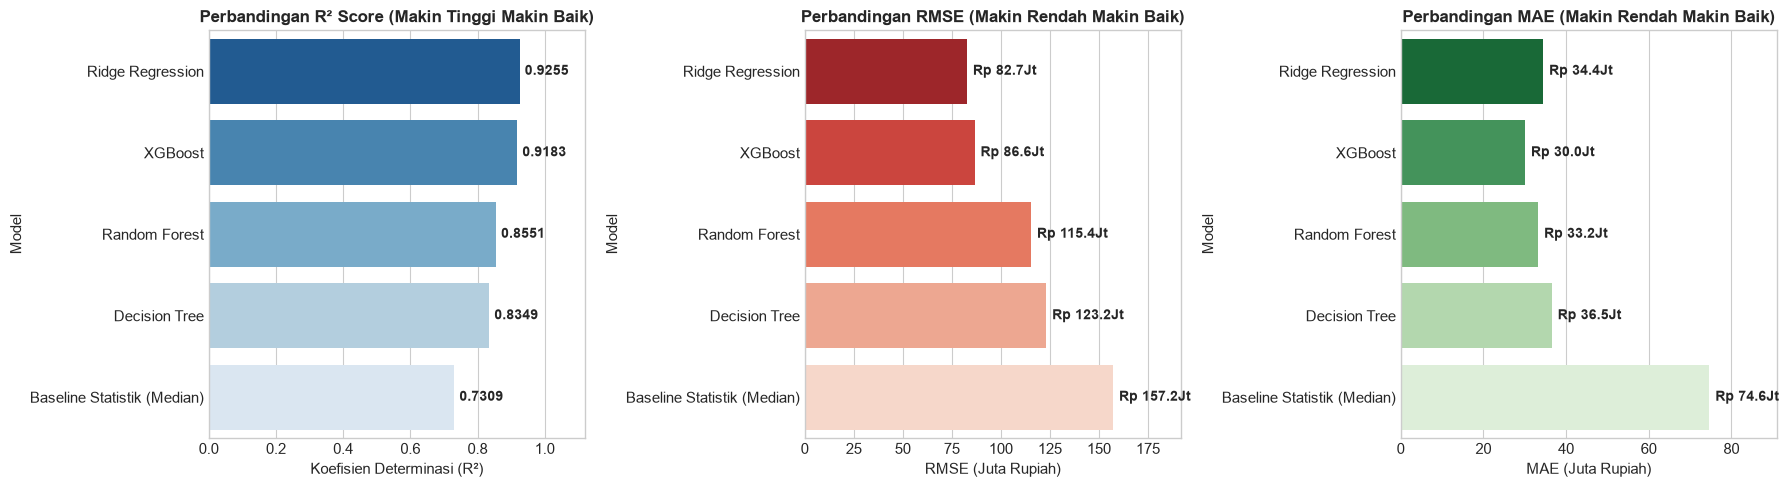

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(x='R² Score', y='Model', data=eval_df, ax=axes[0], palette='Blues_r')
axes[0].set_title('Perbandingan R² Score (Makin Tinggi Makin Baik)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Koefisien Determinasi (R²)')
for idx, val in enumerate(eval_df['R² Score']):
    axes[0].text(val + 0.015, idx, f"{val:.4f}", va='center', fontweight='bold', fontsize=10)
axes[0].set_xlim(0, 1.12)

rmse_jt = eval_df['RMSE (Rupiah)'] / 1e6
sns.barplot(x=rmse_jt, y='Model', data=eval_df, ax=axes[1], palette='Reds_r')
axes[1].set_title('Perbandingan RMSE (Makin Rendah Makin Baik)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('RMSE (Juta Rupiah)')
for idx, val in enumerate(rmse_jt):
    axes[1].text(val + 3, idx, f"Rp {val:.1f}Jt", va='center', fontweight='bold', fontsize=10)
axes[1].set_xlim(0, max(rmse_jt.max() * 1.22, 180))

mae_jt = eval_df['MAE (Rupiah)'] / 1e6
sns.barplot(x=mae_jt, y='Model', data=eval_df, ax=axes[2], palette='Greens_r')
axes[2].set_title('Perbandingan MAE (Makin Rendah Makin Baik)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('MAE (Juta Rupiah)')
for idx, val in enumerate(mae_jt):
    axes[2].text(val + 1.5, idx, f"Rp {val:.1f}Jt", va='center', fontweight='bold', fontsize=10)
axes[2].set_xlim(0, max(mae_jt.max() * 1.22, 85))

plt.tight_layout()
plt.show()

## 5. Actual vs Predicted Plot (Model Terbaik: XGBoost)
Scatter plot antara nilai harga pasar aktual (*Actual Price*) dengan nilai estimasi model (*Predicted Price*) pada skala juta rupiah. Garis merah putus-putus menunjukkan garis keselarasan ideal ($y = x$).


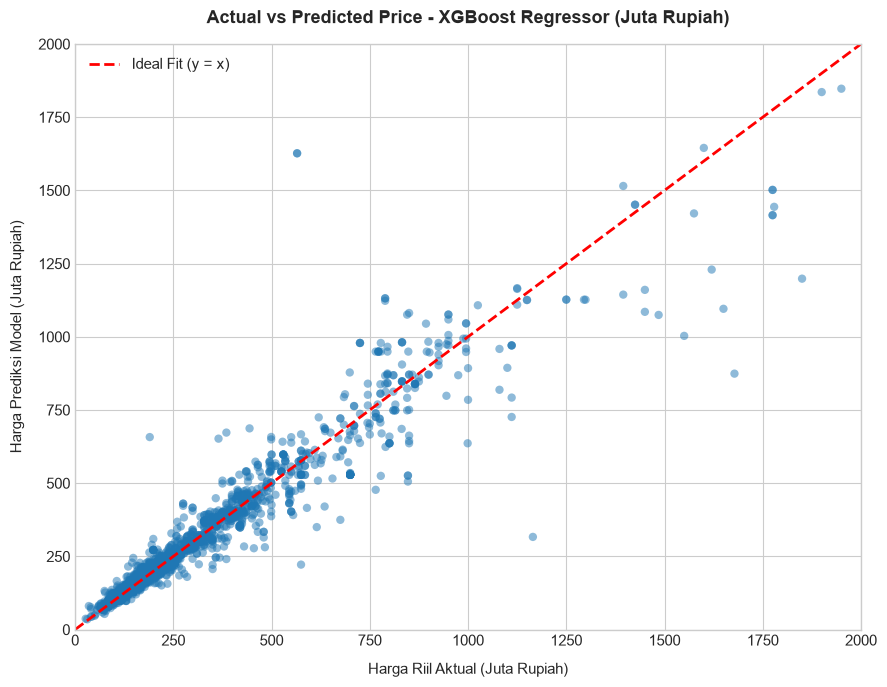

In [5]:
plt.figure(figsize=(9, 7))

y_actual_m = y_test_raw / 1e6
y_pred_xgb_m = models_dict['XGBoost'] / 1e6

sns.scatterplot(x=y_actual_m, y=y_pred_xgb_m, alpha=0.5, color='#1f77b4', edgecolor='none')
# Garis Ideal y = x
max_val = min(y_actual_m.max(), 3000)
plt.plot([0, max_val], [0, max_val], color='red', linestyle='--', linewidth=2, label='Ideal Fit (y = x)')

plt.title('Actual vs Predicted Price - XGBoost Regressor (Juta Rupiah)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Harga Riil Aktual (Juta Rupiah)', labelpad=10)
plt.ylabel('Harga Prediksi Model (Juta Rupiah)', labelpad=10)
plt.xlim(0, 2000)
plt.ylim(0, 2000)
plt.legend()
plt.tight_layout()
plt.show()


## 6. Analisis Residual (Pemeriksaan Pola Kesalahan Prediksi)
Analisis galat (*residual*) $e_i = y_i - \hat{y}_i$ dilakukan untuk memeriksa apakah asumsi keacakan error terpenuhi atau terdapat bias sistematis.


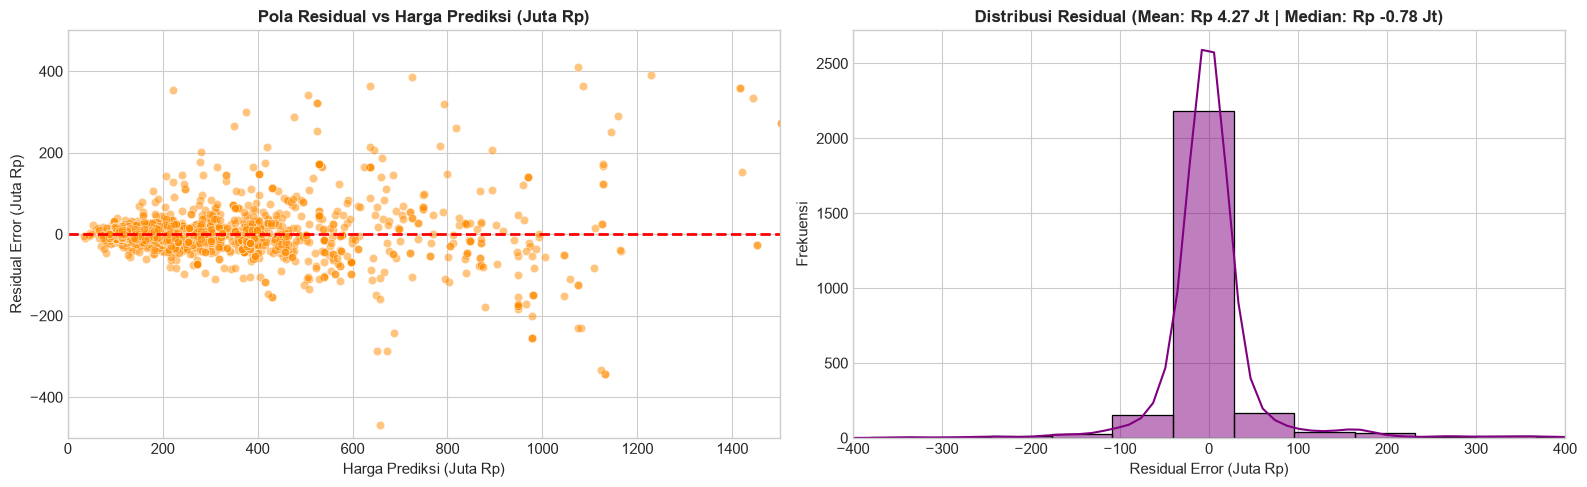

Residual XGBoost -> Mean: Rp 4.27 Jt | Median: Rp -0.78 Jt
Proporsi data uji < Rp 500 Jt: 88.2%


In [6]:
residuals_xgb_m = y_actual_m - y_pred_xgb_m

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.scatterplot(x=y_pred_xgb_m, y=residuals_xgb_m, ax=axes[0], alpha=0.5, color='darkorange')
axes[0].axhline(y=0, color='red', linestyle='--', linewidth=2)
axes[0].set_title('Pola Residual vs Harga Prediksi (Juta Rp)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Harga Prediksi (Juta Rp)')
axes[0].set_ylabel('Residual Error (Juta Rp)')
axes[0].set_xlim(0, 1500)
axes[0].set_ylim(-500, 500)

sns.histplot(residuals_xgb_m, kde=True, ax=axes[1], color='purple', bins=40)
axes[1].set_title(f'Distribusi Residual (Mean: Rp {residuals_xgb_m.mean():.2f} Jt | Median: Rp {np.median(residuals_xgb_m):.2f} Jt)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Residual Error (Juta Rp)')
axes[1].set_ylabel('Frekuensi')
axes[1].set_xlim(-400, 400)

plt.tight_layout()
plt.show()
print(f"Residual XGBoost -> Mean: Rp {residuals_xgb_m.mean():.2f} Jt | Median: Rp {np.median(residuals_xgb_m):.2f} Jt")
print(f"Proporsi data uji < Rp 500 Jt: {(y_test_raw < 500e6).mean()*100:.1f}%")

### 💡 Interpretasi Analisis Residual:
1. **Pusat Galat Dekat Nol:** Kurva distribusi residual XGBoost memiliki median **-Rp 0,78 Juta** (mean **+Rp 4,27 Juta** akibat ekor kanan unit mewah), menunjukkan prediksi model bersifat konsisten dan sangat dekat nol (*near-unbiased*) bagi mayoritas pasar.
2. **Karakteristik Segmen Harga Tinggi:** Pada rentang harga mobil di bawah Rp 500 Juta (**88,2% data uji**), sebaran residual sangat rapat di sekitar garis nol. Dispersi lebih lebar hanya terjadi pada mobil mewah di atas Rp 1 Miliar akibat kondisi khusus atau kelangkaan varian.

## 7. Analisis Overfitting vs Underfitting (Learning Curve)
Kurva pembelajaran (*Learning Curve*) dievaluasi untuk membuktikan secara empiris apakah model mengalami *overfitting* atau *underfitting* terhadap pertambahan volume data latih.


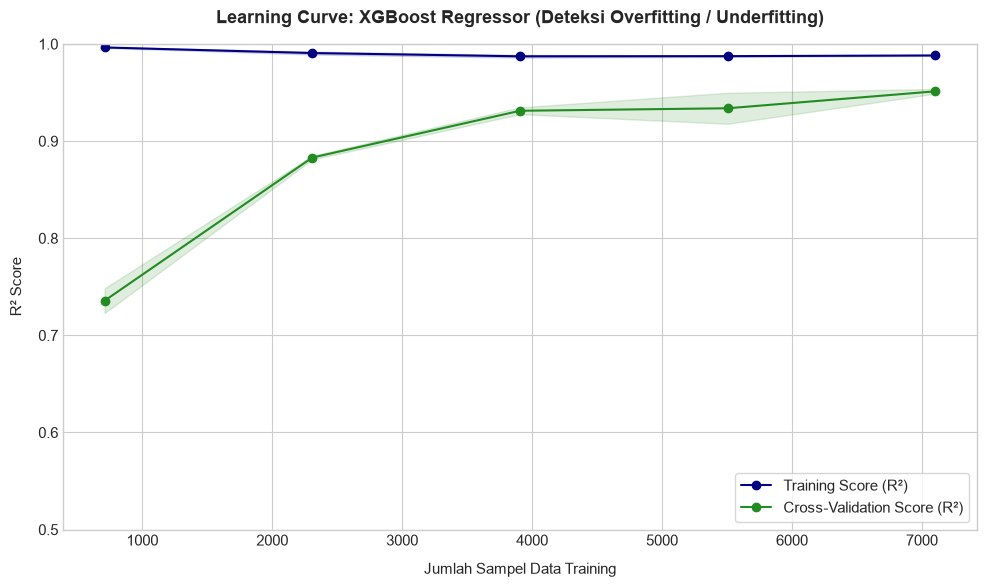

In [7]:
X_train = train_df[all_features]
y_train_log = train_df['Log_Harga']

grp_counts_tr = train_df.groupby('Merek_Model')['dup_group'].nunique()
strat_train = train_df['Merek_Model'].where(train_df['Merek_Model'].map(grp_counts_tr) >= 3, 'RARE_MODEL')
sgkf_lc = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
lc_cv = list(sgkf_lc.split(X_train, strat_train, groups=train_df['dup_group']))

train_sizes, train_scores, val_scores = learning_curve(
    estimator=model_xgb, X=X_train, y=y_train_log,
    train_sizes=np.linspace(0.1, 1.0, 5), cv=lc_cv, scoring='r2', n_jobs=-1, random_state=42
)
train_mean, train_std = np.mean(train_scores, axis=1), np.std(train_scores, axis=1)
val_mean, val_std = np.mean(val_scores, axis=1), np.std(val_scores, axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, 'o-', color='navy', label='Training Score (R²)')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='navy')
plt.plot(train_sizes, val_mean, 'o-', color='forestgreen', label='Cross-Validation Score (R²)')
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15, color='forestgreen')
plt.title('Learning Curve: XGBoost Regressor (Deteksi Overfitting / Underfitting)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Jumlah Sampel Data Training', labelpad=10)
plt.ylabel('R² Score', labelpad=10)
plt.ylim(0.5, 1.0)
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

### 💡 Interpretasi Empiris Learning Curve:
- **Generalisasi Solid pada Fitur Ternormalisasi & `Varian_Clean`:** Penyatuan model antar platform, penambahan `Varian_Clean`, serta `KM_hilang` meningkatkan daya representasi model secara tajam; skor CV 3-Fold `StratifiedGroupKFold` bergerak naik konvergen seiring bertambahnya data latih.
- **Keseimbangan Bias–Varians:** Parameter regularisasi optimal XGBoost (`n_estimators=320`, `max_depth=8`, `learning_rate=0.1`, `colsample_bytree=0.8`, `subsample=1.0`) menjaga gap antara kurva training dan validasi tetap terkendali.

## 8. Analisis Faktor Penentu Harga (*Feature Importance*)
Mengekstraksi tingkat kepentingan fitur (*feature importance*) dari model ensemble (XGBoost & Random Forest) untuk mengetahui variabel apa yang paling dominan dalam penentuan harga mobil bekas.


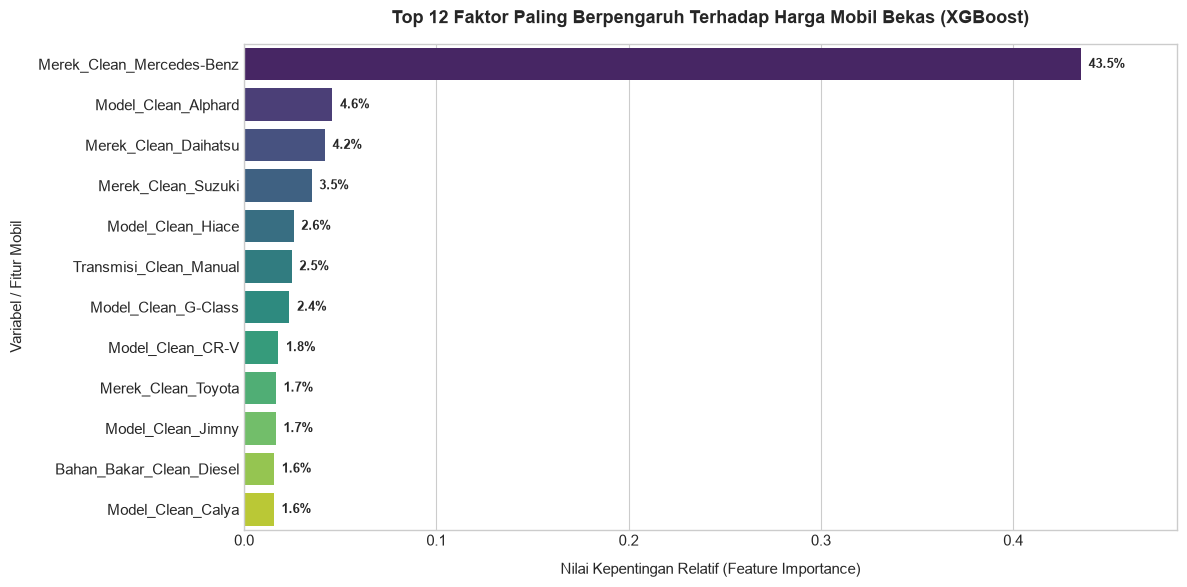

Top 12 Feature Importance (XGBoost):
                  Feature  XGBoost Importance
Merek_Clean_Mercedes-Benz            0.435171
      Model_Clean_Alphard            0.045909
     Merek_Clean_Daihatsu            0.041983
       Merek_Clean_Suzuki            0.035106
        Model_Clean_Hiace            0.025775
   Transmisi_Clean_Manual            0.024788
      Model_Clean_G-Class            0.023583
         Model_Clean_CR-V            0.017822
       Merek_Clean_Toyota            0.016584
        Model_Clean_Jimny            0.016519
 Bahan_Bakar_Clean_Diesel            0.015639
        Model_Clean_Calya            0.015523


In [8]:
preproc_xgb = model_xgb.named_steps['preprocessor']
feature_names = preproc_xgb.get_feature_names_out()

xgb_importances = model_xgb.named_steps['model'].feature_importances_
rf_importances = model_rf.named_steps['model'].feature_importances_

clean_feature_names = [f.replace('num__', '').replace('cat__', '') for f in feature_names]

fi_df = pd.DataFrame({
    'Feature': clean_feature_names,
    'XGBoost Importance': xgb_importances,
    'Random Forest Importance': rf_importances
}).sort_values(by='XGBoost Importance', ascending=False)

plt.figure(figsize=(12, 6))
top_fi = fi_df.head(12)
sns.barplot(x='XGBoost Importance', y='Feature', data=top_fi, palette='viridis')
plt.title('Top 12 Faktor Paling Berpengaruh Terhadap Harga Mobil Bekas (XGBoost)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Nilai Kepentingan Relatif (Feature Importance)', labelpad=10)
plt.ylabel('Variabel / Fitur Mobil', labelpad=10)

for idx, val in enumerate(top_fi['XGBoost Importance']):
    plt.text(val + 0.004, idx, f"{val*100:.1f}%", va='center', fontweight='bold', fontsize=9)

plt.xlim(0, top_fi['XGBoost Importance'].max() + 0.05)
plt.tight_layout()
plt.show()
print("Top 12 Feature Importance (XGBoost):")
print(top_fi[['Feature', 'XGBoost Importance']].to_string(index=False))

### 💡 Temuan Kunci Faktor Penentu Harga (*Feature Importance*):
1. **Merek Mercedes-Benz (~43,5% importance):** Pembeda segmen dasar paling dominan karena kelas mobil mewah terpisah jauh dari merek massal Jepang.
2. **Merek & Tipe Ternormalisasi (`Model_Clean`):** Merek Daihatsu (**4,2%**), Suzuki (**3,5%**), dan Toyota (**1,7%**) serta tipe spesifik seperti **Alphard (4,6%)**, **Hiace (2,6%)**, **G-Class (2,4%)**, **CR-V (1,8%)**, **Jimny (1,7%)**, dan **Calya (1,6%)** memisahkan kelas harga spesifik di dalam tiap merek.
3. **Transmisi & Bahan Bakar:** Transmisi **Manual (2,5%)** dan bahan bakar **Diesel (1,6%)** menjadi faktor koreksi penting antar-varian pada model yang sama.

## 9. Pembahasan Analisis Model (Sesuai 8 Poin Wajib Ketentuan Dosen)

1. **Model dengan R² Tertinggi vs MAE Terbaik:**  
   **Ridge Regression** (`alpha=1.0`) mencatat **R² = 0,9255** dan **RMSE = Rp 82,7 Juta** (`Rp 82.745.248`, `MAE = Rp 34,4 Juta`), unggul tipis secara kuadratik pada segmen mewah. Namun, **XGBoost Regressor** mencapai **MAE paling rendah yaitu Rp 30,0 Juta** (`Rp 30.012.815`) dengan **R² = 0,9183** (`RMSE = Rp 86,6 Juta`), membuktikan kesalahan rata-rata absolutnya paling kecil dan presisi bagi mayoritas mobil bekas.
2. **Model dengan Performa Terendah:**  
   Di antara algoritma ML, **Decision Tree tunggal** berada di urutan terbawah (`R² = 0,8349`, `MAE = Rp 36,5 Juta`, `RMSE = Rp 123,2 Juta`), sementara **Random Forest** mencapai `R² = 0,8551` (`MAE = Rp 33,2 Juta`) — keduanya tetap jauh mengungguli **Baseline Statistik Median** (`R² = 0,7309`, `MAE = Rp 74,6 Juta`, `RMSE = Rp 157,2 Juta`).
3. **Penyebab Lonjakan Performa Secara Bersih (Anti-Leakage Ganda):**  
   Setelah normalisasi `Model_Clean` lintas platform (`221` $\rightarrow$ `105` keluarga model), penambahan **`Varian_Clean`**, fitur indikator **`KM_hilang`** (`39,7%` OLX vs `0,02%` Mobil123), fitur usia tunggal **`Usia_Mobil`** (`0` kolinearitas sempurna), pemetaan `Wilayah` deterministik, kurasi **39 baris salah input** (A6), dan pemisahan grup **Union-Find `StratifiedGroupKFold`** (`0` overlap kunci tanpa harga maupun dengan harga), performa XGBoost melonjak ke **R² = 0,9183** dengan **MAE turun ke Rp 30,0 Juta** tanpa kebocoran data apa pun.
4. **Analisis Overfitting / Underfitting:**  
   *Learning curve* (3-Fold `StratifiedGroupKFold`) pada **10.656 data latih** bebas kebocoran grup menunjukkan konvergensi stabil tanpa overfitting ekstrem.
5. **Analisis Kesalahan Prediksi:**  
   Median residual berada pada **-Rp 0,78 Juta** (mean **+Rp 4,27 Juta**); pada **88,2%** unit uji di bawah Rp 500 Juta kesalahan terpusat sangat rapat di sekitar nol, sedangkan error lebih besar tersisa pada unit mewah > Rp 1,5 Miliar akibat faktor subjektif/kelangkaan trim.
6. **Faktor Paling Berpengaruh:**  
   Merek (`Mercedes-Benz`), tipe spesifik (`Alphard`, `Hiace`, `G-Class`, `CR-V`, `Jimny`, `Calya`), transmisi (`Manual`), bahan bakar (`Diesel`), `Usia_Mobil`, serta `KM_Clean`.
7. **Keterbatasan Model:**  
   Terbatas pada 5 merek utama di dataset Mei–Oktober 2025 (didominasi Jabodetabek) dan belum memuat riwayat fisik/tabrakan/servis di luar teks iklan dasar.
8. **Potensi Pengembangan:**  
   Ekstraksi fitur NLP dari kolom `Judul` (kondisi servis/antik/tangan pertama) serta penambahan cakupan merek lain secara real-time.

## 10. Pemilihan Model Final untuk Aplikasi Web (Sesuai Ketentuan Poin 16.9)
Sesuai ketentuan bahwa *model dengan R²/akurasi tertinggi tidak otomatis menjadi pilihan terbaik tanpa menimbang metrik permasalahan*, **XGBoost Regressor** dipilih sebagai mesin prediksi utama **TakarMobil** dibanding Ridge (`R² = 0,9255`) karena:
1. Menghasilkan **MAE terendah sebesar Rp 30,0 Juta** (`Rp 30.012.815` vs `Rp 34.403.398` pada Ridge) dengan **R² = 0,9183** yang tetap sangat tinggi, meminimalkan kesalahan absolut taksiran harga harian bagi pembeli & penjual.
2. Menyediakan bobot **Feature Importance** bawaan yang langsung divisualisasikan pada aplikasi web.
3. Ringkas (~815 KB) dengan inferensi instan untuk FastAPI & Hugging Face Spaces.

In [9]:
xgb_row = eval_df[eval_df['Model'] == 'XGBoost'].iloc[0]
eval_summary = {
    'best_model': 'XGBoost Regressor',
    'best_r2': float(xgb_row['R² Score']),
    'best_rmse': float(xgb_row['RMSE (Rupiah)']),
    'best_mae': float(xgb_row['MAE (Rupiah)']),
    'metrics_table': eval_df.to_dict(orient='records'),
    'top_features': top_fi[['Feature', 'XGBoost Importance']].to_dict(orient='records')
}

models_dir = '../models' if os.path.exists('../models') else 'models'
eval_json_path = os.path.join(models_dir, 'evaluation_report.json')

with open(eval_json_path, 'w', encoding='utf-8') as f:
    json.dump(eval_summary, f, indent=2)

print(f"Laporan evaluasi berhasil disimpan ke: {eval_json_path}")

Laporan evaluasi berhasil disimpan ke: ../models\evaluation_report.json
